<a href="https://colab.research.google.com/github/sohyun223/ai-application-2026/blob/main/Week05_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5주차 시연 — 데이터의 병을 진단하고 고치기 (파이프라인 ② 정제·설계)
**AI Application · 스마트모빌리티학과 · 2026-09-30 (녹화 강의)**

녹화 영상의 PART 마다 멈추고 해당 셀을 실행하세요. 4주차의 `my_dataset_v0.npz` 를 읽어 **네 가지 병**(직진 편향·복구 부재·라벨 노이즈·시간 상관)을 진단하고, **증강**(반전·시프트·밝기·노이즈)과 **검증 설계**(run 분할·구간별 MAE)를 적용한 뒤 **v1** 을 저장합니다.

| 셀 | 내용 | 영상 PART |
|---|---|---|
| 1 | v0 로드 (없으면 재생성) | — |
| 2 | 병 ① 직진 편향 — 진단과 리밸런싱 | 2 |
| 3 | 병 ② 복구 부재 — 커버리지와 가장자리 프레임 | 2 |
| 4 | 증강 — 반전·시프트·밝기·노이즈를 눈으로 | 3 |
| 5 | 시프트 gain 의 기하학적 근거 | 3 |
| 6 | run 분할 + 구간별 MAE 리포트 | 4 |
| 7 | 증강 유무 학습 비교 — 오프라인 vs 폐루프 | 4 |
| 8 | v1 저장 + 데이터 카드 | 5 |

**준비물**: `tinytrack.py`, 4주차 `my_dataset_v0.npz` (Drive `AIApp/week04`). CPU 로 전체 8분 안팎.

In [ ]:
# ============ 0. 패키지 + tinytrack + Drive (재접속 시 여기부터) ============
import importlib.util, subprocess, sys, os, time, json
for pkg in ["onnx", "onnxruntime"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
try:
    import tinytrack as tt
except ImportError:
    from google.colab import files
    print("tinytrack.py 를 업로드하세요"); files.upload(); import tinytrack as tt
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/AIApp")
except Exception:
    ROOT = Path("./outputs")
SAVE_DIR = ROOT / "week05"; SAVE_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
print("tinytrack", tt.__version__, "| 저장:", SAVE_DIR)

tinytrack.py 를 업로드하세요


Saving tinytrack.py to tinytrack.py
Mounted at /content/drive
tinytrack 0.3.1 | 저장: /content/drive/MyDrive/AIApp/week05


## 1. v0 로드 — 없으면 재생성
4주차에 저장한 `week04/my_dataset_v0.npz` 를 읽습니다. 없으면(또는 로컬이면) 같은 구성으로 빠르게 다시 만듭니다.

In [ ]:
v0_path = ROOT / "week04" / "my_dataset_v0.npz"
if v0_path.exists():
    v0 = tt.load_npz(v0_path); print("v0 로드:", v0["meta"].get("author"), v0["images"].shape)
else:
    print("v0 가 없어 재생성합니다 (약 20초)")
    parts = [tt.collect(tt.ExpertPolicy(), tt.Track.preset(n), 500, seed=10 * ord(n) + k, noise_inject=ni)
             for n in "ABC" for k, ni in enumerate([0.0, 0.3, 0.6])]
    v0 = tt.merge(*parts); v0["meta"] = {"author": "regenerated"}
S0 = tt.summarize(v0); print(S0)

v0 로드: 학번_이름 (4500, 66, 200, 3)
{'n': 4500, 'runs': 10, 'straight_frac': 0.30622222222222223, 'abs_d_max': 0.499332457780838, 'abs_d_mean': 0.05897707864642143, 'edge_frac': 0.013333333333333334}


## 2. 병 ① 직진 편향 — 진단과 리밸런싱
`|steer| < 0.1` 비율이 직진 편향 지표입니다. `rebalance()` 는 과다한 구간을 잘라 히스토그램을 평평하게 만듭니다 (언더샘플링). **검증셋에는 적용하지 않습니다.**

/tmp/ipykernel_847/3348588353.py:6: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_847/3348588353.py:6: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_847/3348588353.py:6: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_847/3348588353.py:6: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(byt

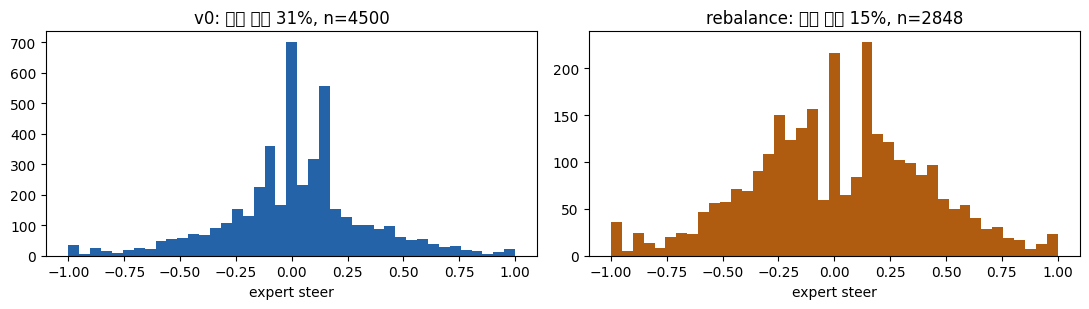

프레임 손실: 37%  (과제 기준: 직진 ≤ 25%, 손실 ≤ 50%)


In [ ]:
v0_rb = tt.rebalance(v0, n_bins=21)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(v0["steers"], bins=41, color="#2563A8"); axes[0].set_title(f"v0: 직진 비율 {S0['straight_frac']:.0%}, n={S0['n']}")
axes[1].hist(v0_rb["steers"], bins=41, color="#B05C10"); axes[1].set_title(f"rebalance: 직진 비율 {tt.summarize(v0_rb)['straight_frac']:.0%}, n={len(v0_rb['steers'])}")
for ax in axes: ax.set_xlabel("expert steer")
plt.tight_layout(); plt.show()
print(f"프레임 손실: {1 - len(v0_rb['steers'])/len(v0['steers']):.0%}  (과제 기준: 직진 ≤ 25%, 손실 ≤ 50%)")

## 3. 병 ② 복구 부재 — 커버리지
상태 `(d, psi)` 산점도로 "정책이 갈 법한 상태"를 얼마나 덮는지 봅니다. 노이즈 주입 수준별로 색을 달리 했습니다 (v0 의 parts 순서: 트랙별 0 / 0.3 / 0.6).

/tmp/ipykernel_847/2114522716.py:7: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.colorbar(sc, ax=ax); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/2114522716.py:7: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  plt.colorbar(sc, ax=ax); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/2114522716.py:7: UserWarning: Glyph 52964 (\N{HANGUL SYLLABLE KEO}) missing from font(s) DejaVu Sans.
  plt.colorbar(sc, ax=ax); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/2114522716.py:7: UserWarning: Glyph 48260 (\N{HANGUL SYLLABLE BEO}) missing from font(s) DejaVu Sans.
  plt.colorbar(sc, ax=ax); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/2114522716.py:7: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.colorbar(sc, ax=ax); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/2114522716.py:7: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s

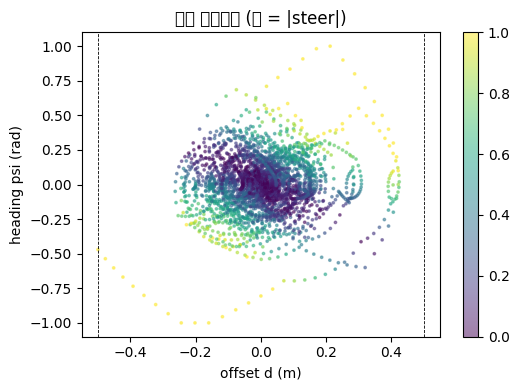

|d| in [0, 0.1): 76.4%  (3436 프레임)
|d| in [0.1, 0.3): 22.3%  (1004 프레임)
|d| in [0.3, 0.5):  1.3%  (60 프레임)


/content/tinytrack.py:453: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 47532 (\N{HANGUL SYLLABLE RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 54532 (\N{HANGUL SYLLABLE PEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 47112 (\N{HANGUL SYLLABLE RE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51076 (\N{HANGUL SYLLABLE IM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/content/tinytrack.py:453: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I

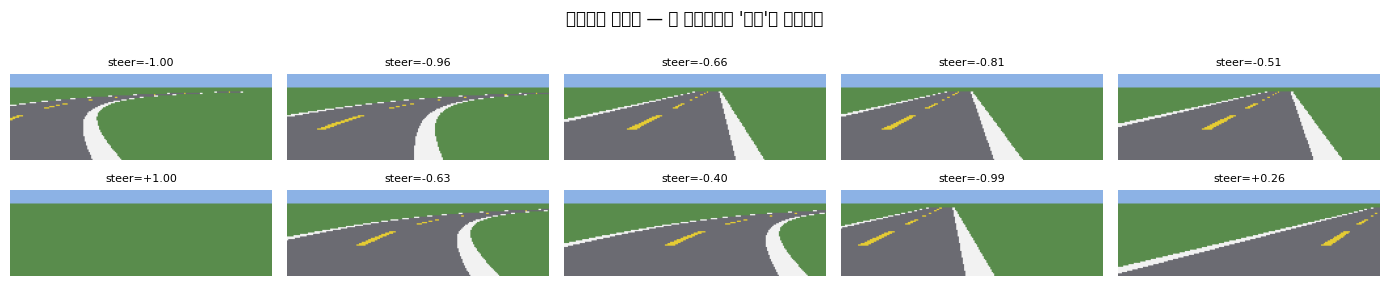

In [ ]:
st = v0["states"]; runs = v0["run_id"]
# v0 는 트랙 3 × 노이즈 3 = 9 파트 순서로 병합됨. 파트 경계는 run_id 로 근사 대신, |d| 로 커버리지를 요약
fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(st[:, 0], st[:, 1], c=np.abs(v0["steers"]), s=3, cmap="viridis", alpha=0.5)
ax.axvline(0.5, ls="--", color="k", lw=0.6); ax.axvline(-0.5, ls="--", color="k", lw=0.6)
ax.set_xlabel("offset d (m)"); ax.set_ylabel("heading psi (rad)"); ax.set_title("상태 커버리지 (색 = |steer|)")
plt.colorbar(sc, ax=ax); plt.tight_layout(); plt.show()
for lo, hi in [(0, 0.1), (0.1, 0.3), (0.3, 0.5)]:
    m = (np.abs(st[:, 0]) >= lo) & (np.abs(st[:, 0]) < hi)
    print(f"|d| in [{lo}, {hi}): {m.mean():5.1%}  ({m.sum()} 프레임)")
edge = np.where(np.abs(st[:, 0]) > 0.3)[0]
tt.show_frames(v0["images"], v0["steers"], n=10, idx=edge[np.linspace(0, len(edge)-1, min(10, len(edge))).astype(int)],
               title="가장자리 프레임 — 이 이미지들이 '복구'를 가르친다"); plt.show()

## 4. 증강 — 라벨과 함께 바꾸기
- **반전**: 이미지 좌우 반전 + 조향 부호 반전
- **시프트**: 이미지를 오른쪽으로 dx 밀면 차선이 오른쪽에 = 차가 왼쪽에 있는 상황 → 조향을 **+gain·dx** 보정
- **밝기·노이즈**: 라벨 불변

/tmp/ipykernel_847/93770423.py:21: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  plt.suptitle("기하 증강은 라벨이 바뀌고, 외관 증강은 라벨이 그대로"); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/93770423.py:21: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.suptitle("기하 증강은 라벨이 바뀌고, 외관 증강은 라벨이 그대로"); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/93770423.py:21: UserWarning: Glyph 51340 (\N{HANGUL SYLLABLE JWA}) missing from font(s) DejaVu Sans.
  plt.suptitle("기하 증강은 라벨이 바뀌고, 외관 증강은 라벨이 그대로"); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/93770423.py:21: UserWarning: Glyph 50864 (\N{HANGUL SYLLABLE U}) missing from font(s) DejaVu Sans.
  plt.suptitle("기하 증강은 라벨이 바뀌고, 외관 증강은 라벨이 그대로"); plt.tight_layout(); plt.show()
/tmp/ipykernel_847/93770423.py:21: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  plt.suptitle("기하 증강은 라벨이 바뀌고, 외관 증강은 라벨이 그대로"); plt.tight_layout(); plt.sho

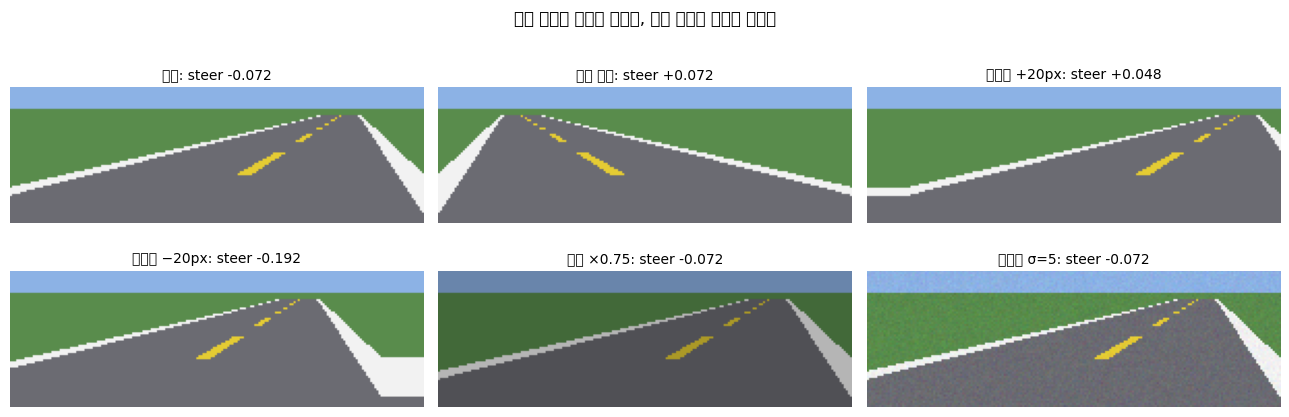

In [ ]:
i = edge[len(edge)//2] if len(edge) else 100
img, s = v0["images"][i], float(v0["steers"][i])
rng = np.random.RandomState(0)
class Fixed:
    def __init__(self, v): self.v = v
    def randint(self, a, b): return self.v
    def rand(self): return 0.0
    def uniform(self, a, b): return 0.75
    def normal(self, m, sd, size=None): return rng.normal(m, sd, size)
samples = [
    ("원본", img, s),
    ("좌우 반전", *tt.aug_flip(img, s, p=1.0, rng=Fixed(0))),
    ("시프트 +20px", *tt.aug_shift(img, s, rng=Fixed(20))),
    ("시프트 −20px", *tt.aug_shift(img, s, rng=Fixed(-20))),
    ("밝기 ×0.75", *tt.aug_brightness(img, s, rng=Fixed(0))),
    ("노이즈 σ=5", *tt.aug_noise(img, s, rng=rng)),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 4.6))
for ax, (name, im, lab) in zip(axes.ravel(), samples):
    ax.imshow(im); ax.axis("off"); ax.set_title(f"{name}: steer {lab:+.3f}", fontsize=10)
plt.suptitle("기하 증강은 라벨이 바뀌고, 외관 증강은 라벨이 그대로"); plt.tight_layout(); plt.show()

## 5. 시프트 gain 의 근거
바닥 행(z≈0.6 m)에서 1 px ≈ z/F_PX ≈ 0.0037 m. 이미지를 +dx 밀면 차가 −dx·0.0037 m 에 있는 것과 같고, 전문가는 −2.0·d 만큼 꺾으므로 Δsteer ≈ +2.0·0.0037·dx ≈ 0.0075·dx. 기본 gain 0.006 은 원근(위쪽 행은 덜 움직임)을 감안한 보수적 값입니다.

In [ ]:
base = tt.render(0, 0, 0); dx = 20
rolled = np.roll(base, dx, axis=1)
lane_col = lambda im, row=60: int(np.argmax(im[row, :, 0] > 200))
cands = {f"d={dd:+.3f}": lane_col(tt.render(dd, 0, 0)) for dd in np.linspace(-0.12, 0.12, 7)}
print(f"롤 +{dx}px 의 차선 위치(px): {lane_col(rolled)}")
print("d 별 차선 위치(px):", cands)
best = min(cands, key=lambda k: abs(cands[k] - lane_col(rolled)))
print(f"→ 가장 비슷한 상태: {best}  (음수 = 차가 왼쪽 → 전문가는 + 조향)")
print(f"이론 gain ≈ 2.0 × {tt.CAM_H*tt.F_PX/ (60-tt.Y_HORIZON) / tt.F_PX:.4f} = {2.0*tt.CAM_H/(60-tt.Y_HORIZON):.4f} /px   (기본값 0.006)")

롤 +20px 의 차선 위치(px): 0
d 별 차선 위치(px): {'d=-0.120': 0, 'd=-0.080': 0, 'd=-0.040': 0, 'd=+0.000': 0, 'd=+0.040': 0, 'd=+0.080': 196, 'd=+0.120': 186}
→ 가장 비슷한 상태: d=-0.120  (음수 = 차가 왼쪽 → 전문가는 + 조향)
이론 gain ≈ 2.0 × 0.0040 = 0.0080 /px   (기본값 0.006)


## 6. run 분할 + 구간별 MAE 리포트
전체 MAE 하나로는 병을 못 봅니다. 직진/좌/우/가장자리 구간으로 나눠 봅니다. 비교 대상으로 **'항상 0' 정책**(직진만 하는 모델)을 둡니다 — 직진 편향이 심한 데이터에서 이 정책의 전체 MAE 가 얼마나 낮게 나오는지 보세요.

In [ ]:
tr, va = tt.split_by_run(v0, val_frac=0.2, seed=0)
assert not set(np.unique(tr["run_id"])) & set(np.unique(va["run_id"]))
print(f"학습 {len(tr['steers'])} / 검증 {len(va['steers'])}  (run 겹침 없음)")

def mae_report(pred, ds):
    y, st = ds["steers"], ds["states"]; err = np.abs(pred - y)
    groups = {"전체": np.ones_like(y, bool), "직진 |y|<0.1": np.abs(y) < 0.1, "좌회전 y>0.3": y > 0.3,
              "우회전 y<-0.3": y < -0.3, "가장자리 |d|>0.3": np.abs(st[:, 0]) > 0.3}
    return {k: (float(err[m].mean()) if m.any() else float("nan"), int(m.sum())) for k, m in groups.items()}

zero_pred = np.zeros_like(va["steers"])
expert_pred = np.array([tt.expert_steer(*s[:3]) for s in va["states"]])
rep0, repE = mae_report(zero_pred, va), mae_report(expert_pred, va)
print(f"{'구간':16s} {'n':>5s}  {'항상 0':>8s}  {'전문가':>8s}")
for k in rep0:
    print(f"{k:16s} {rep0[k][1]:5d}  {rep0[k][0]:8.3f}  {repE[k][0]:8.3f}")
print("→ '항상 0' 은 직진 구간에선 완벽하지만 회전·가장자리에서 크게 틀린다. 전체 MAE 만 보면 이 차이가 가려진다")

학습 3743 / 검증 757  (run 겹침 없음)
구간                   n      항상 0       전문가
전체                 757     0.314     0.000
직진 |y|<0.1         169     0.049     0.000
좌회전 y>0.3          142     0.569     0.000
우회전 y<-0.3         172     0.545     0.000
가장자리 |d|>0.3        39     0.765     0.000
→ '항상 0' 은 직진 구간에선 완벽하지만 회전·가장자리에서 크게 틀린다. 전체 MAE 만 보면 이 차이가 가려진다


## 7. 증강 유무 학습 비교 — 오프라인 vs 폐루프
같은 데이터(리밸런스한 학습셋)로 **증강 없음 / 증강 있음** 두 모델을 짧게 학습해 오프라인 MAE 와 폐루프 score 를 나란히 봅니다. (각 4에폭, CPU 약 1분씩)

In [ ]:
tr_rb, _ = tt.split_by_run(tt.rebalance(v0), val_frac=0.2, seed=0)   # 학습셋만 리밸런스
results = {}
for name, aug in [("no_aug", None), ("aug", tt.make_augment(seed=0))]:
    t0 = time.time(); m = tt.make_model()
    hist = tt.train_bc(m, tr_rb, va, epochs=4, batch=64, augment=aug, verbose=False)
    onnx = tt.export_onnx(m, SAVE_DIR / f"w5_{name}.onnx"); pol = tt.OnnxPolicy(onnx)
    mae, pred, idx = tt.offline_mae(pol, va)
    ev = tt.evaluate(pol, ["A", "B"], max_steps=800)
    results[name] = dict(val_mse=hist["val"][-1], mae=mae, score=ev["score"], completion=ev["completion"], sec=time.time()-t0)
    rep = mae_report(np.array([pol(va["images"][i]) for i in range(len(va["steers"]))]), va)
    print(f"{name:7s} val_mse={hist['val'][-1]:.4f} MAE={mae:.3f} | 가장자리 MAE={rep['가장자리 |d|>0.3'][0]:.3f} | 폐루프 score={ev['score']:.1f} comp={ev['completion']:.2f}  ({time.time()-t0:.0f}s)")
with open(SAVE_DIR / "aug_compare.json", "w") as f: json.dump(results, f, indent=1)
print("→ 오프라인 MAE 차이보다 폐루프 score 차이가 큰지 확인. 실험 기록표의 첫 두 행입니다")

no_aug  val_mse=0.0427 MAE=0.083 | 가장자리 MAE=0.368 | 폐루프 score=9.9 comp=0.21  (61s)
aug     val_mse=0.0139 MAE=0.058 | 가장자리 MAE=0.182 | 폐루프 score=88.8 comp=1.00  (73s)
→ 오프라인 MAE 차이보다 폐루프 score 차이가 큰지 확인. 실험 기록표의 첫 두 행입니다


## 8. v1 저장 + 데이터 카드
v1 = 리밸런스한 v0 (+ 학습 시 증강은 로더에서). **v0 는 그대로 두고** 새 파일로 저장합니다.

In [ ]:
v1 = tt.rebalance(v0, n_bins=21)
card = dict(name="my_dataset_v1", from_version="v0", author=v0.get("meta", {}).get("author", "unknown"),
            created=time.strftime("%Y-%m-%d"), changes=["rebalance(n_bins=21)"], augment_at_train=["flip", "shift(gain=0.006)", "brightness", "noise"],
            summary=tt.summarize(v1))
size = tt.save_npz(SAVE_DIR / "my_dataset_v1.npz", v1, **{k: v for k, v in card.items() if k != "summary"})
json.dump(card, open(SAVE_DIR / "my_dataset_v1.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print(f"저장: {SAVE_DIR/'my_dataset_v1.npz'} ({size/1e6:.1f} MB) — 직진 비율 {card['summary']['straight_frac']:.0%}, n={card['summary']['n']}")
print("다시 읽기:", tt.load_npz(SAVE_DIR / "my_dataset_v1.npz")["meta"]["name"])

저장: /content/drive/MyDrive/AIApp/week05/my_dataset_v1.npz (1.1 MB) — 직진 비율 15%, n=2848
다시 읽기: my_dataset_v1


## 정리
- 병 ①: 직진 편향은 히스토그램과 `straight_frac` 으로 진단, `rebalance` 로 처방 (검증셋 제외).
- 병 ②: 복구 부재는 상태 커버리지로 진단, 노이즈 주입(hold)과 시프트 증강으로 처방.
- 증강: 기하 증강은 라벨을 함께 바꾼다 (반전 부호, 시프트 **+gain·dx**). 외관 증강은 라벨 불변.
- 검증: run 분할 + 구간별 MAE. '항상 0' 이 전체 MAE 를 얼마나 속이는지 봤다. 최종 판단은 폐루프.

**과제 2** (`과제2_데이터정제.ipynb`): 위 절차를 빈칸 채우기로 직접 구현 → v1 + 리포트. 마감 10/6(화) 23:59.
**다음 주(6주차, 10/7)**: 베이스 미세조정 → ONNX → 첫 폐루프 주행. v1 npz 가 Drive 에 있어야 합니다.